# Croisement avec le nombre de licenciés et autres variables socio-économico-démographiques

In [62]:
import pandas as pd
import requests

url = "https://data.sports.gouv.fr/api/explore/v2.1/catalog/datasets/lics_dep/records"

params = {
    "where": "federations_sportives = 'Fédération Française de Football'",
    "select": "dep, dep_name, lics, pop, annee",
    "order_by": "dep",
    "limit": 100,
    "offset": 0,
}

toutes_les_lignes = []

while True:
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    data = response.json()
    lignes = data["results"]

    if not lignes:
        break

    toutes_les_lignes.extend(lignes)
    params["offset"] += params["limit"]

df_licences_football = pd.DataFrame(toutes_les_lignes)

print(f"Nombre de résultats récupérés : {len(df_licences_football)}")

Nombre de résultats récupérés : 110


In [63]:
df_licences_football.head()

,dep,dep_name,lics,pop,annee
0,01,Ain,25644,683034.0,2024
1,02,Aisne,21159,521152.0,2024
2,2A,Corse-du-Sud,4969,170513.0,2024
3,2B,Haute-Corse,6650,186724.0,2024
4,03,Allier,14161,333234.0,2024


In [64]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import fonctions
from fonctions import *

#Un exemple de lien pour obtenir le nombre d'infrastructures par département à l'aide de la méthode group_by et renommé sous la varibale nb_infra
api_url = "https://equipements.sports.gouv.fr/api/explore/v2.1/catalog/datasets/data-es/records?select=COUNT(inst_numero)%20as%20nb_infra&group_by=dep_nom&order_by=dep_code&limit=-1"
tab = call_api(api_url)
tab.head(3)

dict_keys(['total_count', 'results'])


,dep_nom,nb_infra
0,NaN,170
1,Ain,4102
2,Aisne,3635


In [65]:
colonnes = [
    "inst_numero",
    "inst_nom",
    "dep_nom",
    "dep_code_filled",
    "new_code",
    "equip_type_code",
    "equip_type_name",
    "equip_x",
    "equip_y",
]

In [66]:
#Cette cellule prend environ 1m30 à être exécutée, elle appelle tous les équipements sur les 31 caractéristiques précedemment identifiées.
url = creer_url_api(colonnes)

print(url)

recensement = call_csv(url)
recensement.head(3)

https://equipements.sports.gouv.fr/api/explore/v2.1/catalog/datasets/data-es/records?select=inst_numero%2Cinst_nom%2Cdep_nom%2Cdep_code_filled%2Cnew_code%2Cequip_type_code%2Cequip_type_name%2Cequip_x%2Cequip_y&limit=-1


/Users/a33630/Python-data-science/fonctions.py:53: DtypeWarning: Columns (0: dep_code_filled, 1: new_code) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(


,inst_numero,inst_nom,dep_nom,dep_code_filled,new_code,equip_type_code,equip_type_name,equip_x,equip_y
0,I2A0010001,Stade municipal d'AFA,Corse-du-Sud,2A,2A001,2201,Salles polyvalentes / des fêtes / non spéciali...,8.798290,41.98762
1,I2A0010001,Stade municipal d'AFA,Corse-du-Sud,2A,2A001,2802,Terrain de football,8.798784,41.98740
2,I2A0040001,Ecole primaire les jardins de l'empereur,Corse-du-Sud,2A,2A004,2901,Terrain de basket-ball,8.726578,41.92717


In [67]:
terrains_football = recensement[recensement["equip_type_code"] == 2802]
print(f"Nombre de terrains de football : {len(terrains_football)}")

terrains_football = terrains_football.dropna()
print(f"Nombre de terrains de football : {len(terrains_football)}")

Nombre de terrains de football : 36352
Nombre de terrains de football : 36318


In [68]:
import geopandas as gpd
from cartiflette import carti_download

departements = carti_download(
    values="France",
    crs=4326,
    borders="DEPARTEMENT",
    vectorfile_format="geojson",
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2022,
)

#Passage en espg 2154 : Lambert 93 pour avoir des surfaces en m²
departements = departements.to_crs(epsg=2154)

# Ajout de l'aire en km²
departements['AREA'] = departements.area.div(1e6)

In [69]:
#Correction des polygones cartiflette pour n'avoir qu'un polygone par département
departements = departements.dissolve(by='INSEE_DEP')
departements = departements.reset_index()

departements['INSEE_DEP'] = departements['INSEE_DEP'].astype(str)

In [70]:
data_eco = pd.read_csv('data_eco.csv', delimiter=';', skiprows= 2)
data_eco.head(4)

,Code,Libellé,Rapport interdécile du niveau de vie (9e déc./1er déc.) 2021,Part des ménages fiscaux imposés 2021,Médiane du niveau de vie 2021
0,01,Ain,3.5,55.2,24810
1,02,Aisne,3.1,45.2,20920
2,03,Allier,3,45.3,21500
3,04,Alpes-de-Haute-Provence,3.2,47.3,21790


In [71]:
import copy

#Faire une copie pour ne pas enlever les départements dans le dataset initial
departements_eco = copy.deepcopy(departements)

#To merge cartiflette data and the database imported
departements_eco = departements_eco.merge(data_eco, left_on="INSEE_DEP", right_on="Code", how="left")

#Nettoyage de données : retirer les départements dont les données ne sont pas disponibles
departements_eco['Médiane du niveau de vie 2021'] = departements_eco['Médiane du niveau de vie 2021'].replace('N/A - résultat non disponible',np.nan).astype(float)
departements_eco= departements_eco.dropna(subset=['Médiane du niveau de vie 2021'])

#Conversion en format numérique
departements_eco['Rapport interdécile du niveau de vie (9e déc./1er déc.) 2021'] = departements_eco['Rapport interdécile du niveau de vie (9e déc./1er déc.) 2021'].astype(float)
departements_eco.head(2)

,INSEE_DEP,geometry,PAYS,LIBELLE_DEPARTEMENT,POPULATION,SOURCE,AREA,Code,Libellé,Rapport interdécile du niveau de vie (9e déc./1er déc.) 2021,Part des ménages fiscaux imposés 2021,Médiane du niveau de vie 2021
0,01,"POLYGON ((877348.5 6596702.5, 877276.3 6596665...",France,Ain,652432,IGN:EXPRESS-COG-CARTO-TERRITOIRE,5774.258579,01,Ain,3.5,55.2,24810.0
1,02,"POLYGON ((776099.6 6923411.2, 776238.3 6924150...",France,Aisne,531345,IGN:EXPRESS-COG-CARTO-TERRITOIRE,7418.585414,02,Aisne,3.1,45.2,20920.0


In [72]:
import geopandas as gpd
from io import BytesIO

# URL de la ressource (fichier GeoJSON)
url2 = "https://www.data.gouv.fr/fr/datasets/r/eb36371a-761d-44a8-93ec-3d728bec17ce"

# Télécharger le fichier GeoJSON
response = requests.get(url2)

# Charger le fichier dans un GeoDataFrame
gdf = gpd.read_file(BytesIO(response.content))

# Création d'un nouvel objet sans les départements d'outre-mer
gdf_metropole = gdf[~gdf['code_insee'].str.startswith('97')]  # Exclure les départements d'outre-mer

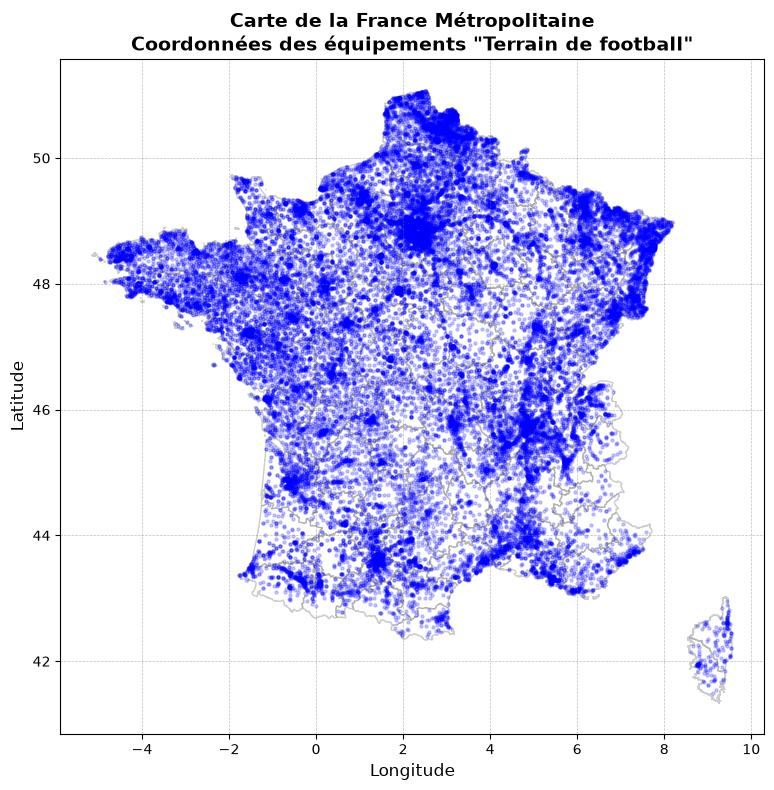

In [73]:
terrains_football_metropole = terrains_football[
    (terrains_football['equip_x'] >= -5) & 
    (terrains_football['equip_x'] <= 10) & 
    (terrains_football['equip_y'] >= 41) & 
    (terrains_football['equip_y'] <= 52)
].copy()

# Tracer la carte
fig, ax = plt.subplots(figsize=(12, 8))

# Fond de carte de la France métropolitaine
gdf_metropole.plot(ax=ax, color='white', edgecolor='gray', alpha=0.4)

# Tracer les points pour le type "Terrain football"
ax.scatter(
    terrains_football_metropole['equip_x'],
    terrains_football_metropole['equip_y'],
    color= 'blue',
    s=5,  # Taille des points
    alpha=0.2,
    label='Terrain de football'
)

# Ajouter les informations sur la carte
plt.title('Carte de la France Métropolitaine\nCoordonnées des équipements "Terrain de football"', fontsize=14, weight='bold')
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.tight_layout()

# Montrer la carte
plt.show()

## Maintenant on crée un df avec tous les départements en ligne

In [74]:
terrains_football.head(3)

,inst_numero,inst_nom,dep_nom,dep_code_filled,new_code,equip_type_code,equip_type_name,equip_x,equip_y
1,I2A0010001,Stade municipal d'AFA,Corse-du-Sud,2A,2A001,2802,Terrain de football,8.798784,41.98740
12,I2A0040009,Centre du Sport de la Jeunesse de Corse,Corse-du-Sud,2A,2A004,2802,Terrain de football,8.759160,41.94644
16,I2A0040011,STADE DU BINDA,Corse-du-Sud,2A,2A004,2802,Terrain de football,8.739880,41.93728


In [75]:
df_licences_terrains = df_licences_football.merge(dep_terrains_football, left_on='dep_name', right_on='dep_nom', how='left')

In [79]:
df_licences_terrains[df_licences_terrains.isna().any(axis=1)].head(10)

,dep,dep_name,lics,pop,annee,dep_nom,nb_terrains_football
100,975,St-Pierre-et-Miquelon,809,NaN,2024,NaN,NaN
102,977,St-Barthélemy,9,NaN,2024,NaN,NaN
103,978,St-Martin,1027,NaN,2024,NaN,NaN
104,980,Monaco,497,NaN,2024,NaN,NaN
105,986,Wallis-et-Futuna,0,NaN,2024,Wallis-et-Futuna,5.0
106,987,Polynésie Française,1,NaN,2024,NaN,NaN
107,988,Nouvelle-Calédonie,5,NaN,2024,Nouvelle-Calédonie,200.0
108,ETR,Etranger,28,NaN,2024,NaN,NaN
109,NR,Non réparti,0,NaN,2024,NaN,NaN


In [81]:
df_licences_terrains = df_licences_terrains.dropna()

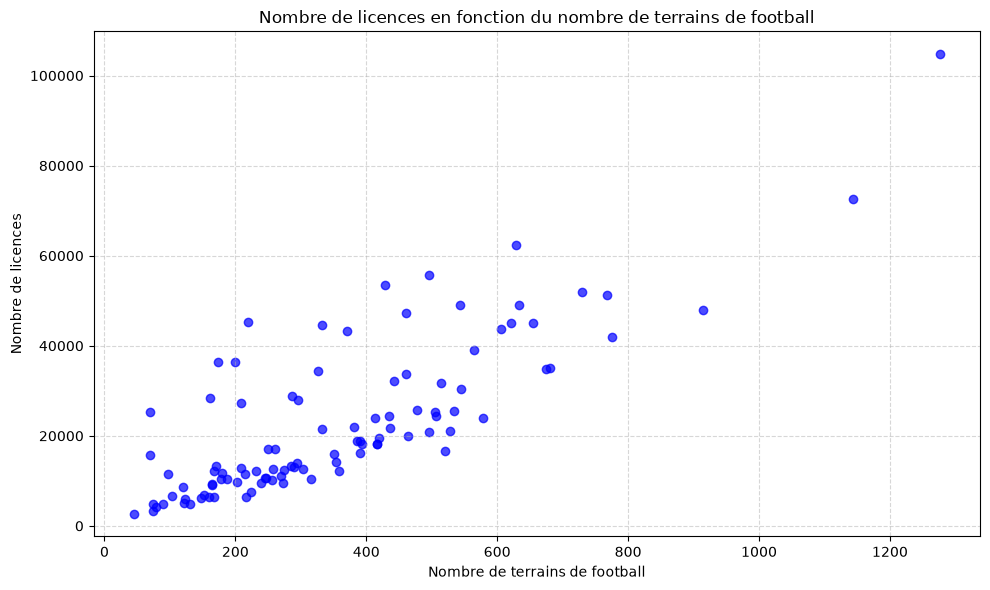

In [91]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_licences_terrains["nb_terrains_football"],
    df_licences_terrains["lics"],
    alpha=0.7,
    color="blue"
)

plt.xlabel("Nombre de terrains de football")
plt.ylabel("Nombre de licences")
plt.title(
    "Nombre de licences en fonction du nombre de terrains de football"
)

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

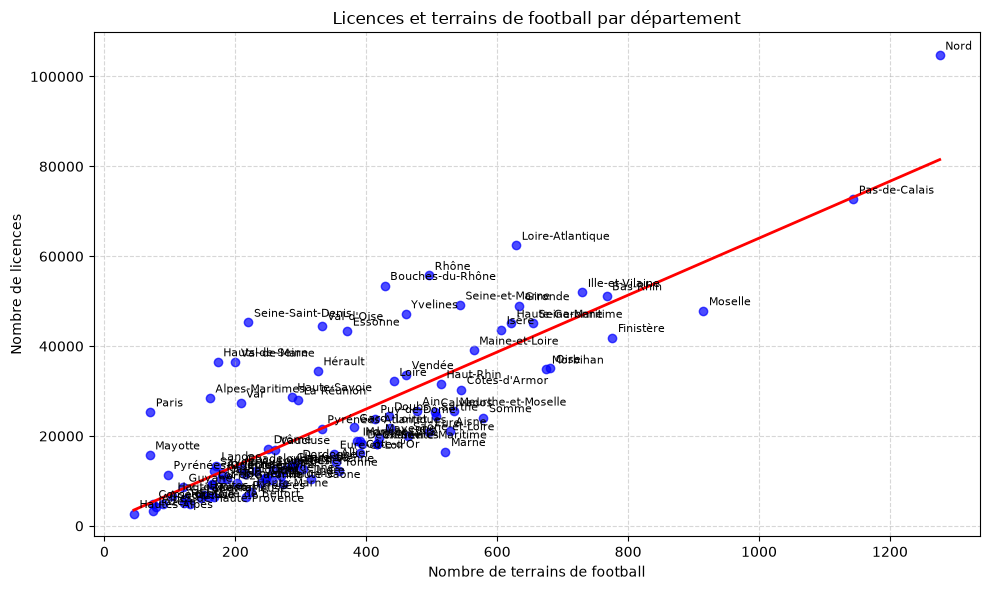

In [94]:
x = df_licences_terrains["nb_terrains_football"].to_numpy()
y = df_licences_terrains["lics"].to_numpy()

# Calcul de la droite : y = a*x + b
a, b = np.polyfit(x, y, 1)

# Valeurs prédites par la droite
x_reg = np.linspace(x.min(), x.max(), 100)
y_reg = a * x_reg + b

plt.figure(figsize=(10, 6))

plt.scatter(
    df_licences_terrains["nb_terrains_football"],
    df_licences_terrains["lics"],
    alpha=0.7,
    color="blue"
)

for _, ligne in df_licences_terrains.iterrows():
    plt.annotate(
        ligne["dep_name"],
        (
            ligne["nb_terrains_football"],
            ligne["lics"]
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.plot(
    x_reg,
    y_reg,
    color="red",
    linewidth=2,
    label=f"Régression : y = {a:.2f}x + {b:.2f}"
)

plt.xlabel("Nombre de terrains de football")
plt.ylabel("Nombre de licences")
plt.title("Licences et terrains de football par département")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [82]:
df_licences_terrains.head()

,dep,dep_name,lics,pop,annee,dep_nom,nb_terrains_football
0,01,Ain,25644,683034.0,2024,Ain,477.0
1,02,Aisne,21159,521152.0,2024,Aisne,528.0
2,2A,Corse-du-Sud,4969,170513.0,2024,Corse-du-Sud,74.0
3,2B,Haute-Corse,6650,186724.0,2024,Haute-Corse,103.0
4,03,Allier,14161,333234.0,2024,Allier,353.0


In [89]:
df_final = df_licences_terrains.merge(departements_eco, left_on='dep_name', right_on='Libellé', how='left')

In [90]:
df_final = df_final.dropna()